## Fractional Knapsack

In [3]:

def fractional_knapsack(items, capacity):
    items = sorted(items, key=lambda x: x[0] / x[1],
                   reverse=True)

    total_value = 0.0

    for value, weight in items:
        if capacity <= 0:
            break

        taken = min(weight, capacity)
        total_value += taken * (value / weight)
        capacity -= taken

    return total_value


# Predefined test data
items = [(60, 10), (100, 20), (120, 30)]
capacity = 50

result = fractional_knapsack(items, capacity)
print(f"Maximum obtainable value: {result:.6f}")


Maximum obtainable value: 240.000000


## Activity Selection

In [4]:

def activity_selection(activities):
    # Sort by finishing time
    activities = sorted(activities, key=lambda x: (x[1], x[0]))

    selected = []
    last_finish = float('-inf')

    for start, finish in activities:
        if start >= last_finish:
            selected.append((start, finish))
            last_finish = finish

    return selected


# Predefined test data
activities = [
    (1, 2),
    (3, 4),
    (0, 6),
    (5, 7),
    (8, 9),
    (5, 9)
]

selected = activity_selection(activities)

print("Selected activities:", selected)
print("Maximum number of activities:", len(selected))


Selected activities: [(1, 2), (3, 4), (5, 7), (8, 9)]
Maximum number of activities: 4


## Activity timeline visualization

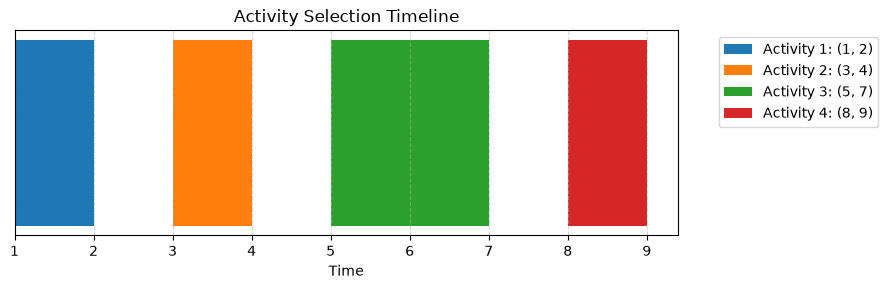

In [5]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 3))

for i, (start, finish) in enumerate(selected):
    plt.barh(
        y=0,
        width=finish - start,
        left=start,
        height=0.35,
        label=f"Activity {i + 1}: ({start}, {finish})"
    )

plt.yticks([])
plt.xlabel("Time")
plt.title("Activity Selection Timeline")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()


## Huffman Compression Size Generator

In [6]:

from collections import Counter
import heapq
import itertools


def huffman_compression_size(text):
    if not text:
        return 0

    frequencies = Counter(text)

    # Each heap entry contains frequency and a unique tie-breaker
    counter = itertools.count()
    heap = [
        (frequency, next(counter), character)
        for character, frequency in frequencies.items()
    ]
    heapq.heapify(heap)

    # Special case: only one unique character
    if len(heap) == 1:
        return len(text)

    total_bits = 0

    while len(heap) > 1:
        freq1, _, node1 = heapq.heappop(heap)
        freq2, _, node2 = heapq.heappop(heap)

        merged_frequency = freq1 + freq2
        total_bits += merged_frequency

        merged_node = (node1, node2)
        heapq.heappush(
            heap,
            (merged_frequency, next(counter), merged_node)
        )

    return total_bits


# Predefined test data
text = "aaabbc"

result = huffman_compression_size(text)

print("Input text:", text)
print("Character frequencies:", dict(Counter(text)))
print("Total compressed size:", result, "bits")


Input text: aaabbc
Character frequencies: {'a': 3, 'b': 2, 'c': 1}
Total compressed size: 9 bits


## Huffman tree visualization

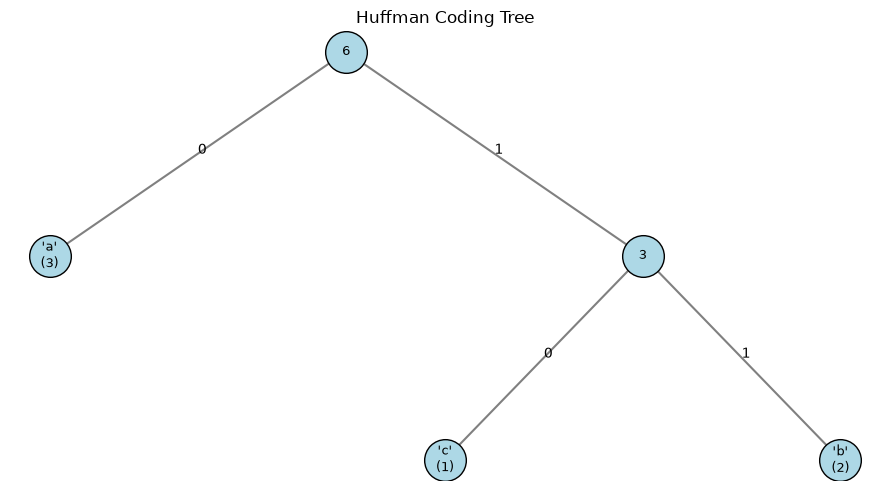

In [7]:

import matplotlib.pyplot as plt
import heapq
import itertools
from collections import Counter


def build_huffman_tree(text):
    frequencies = Counter(text)
    counter = itertools.count()

    heap = [
        (freq, next(counter), char)
        for char, freq in frequencies.items()
    ]
    heapq.heapify(heap)

    if not heap:
        return None

    if len(heap) == 1:
        freq, _, char = heap[0]
        return (char, freq)

    while len(heap) > 1:
        f1, _, left = heapq.heappop(heap)
        f2, _, right = heapq.heappop(heap)

        merged = (left, right)
        heapq.heappush(
            heap,
            (f1 + f2, next(counter), merged)
        )

    return heap[0][2]


def draw_huffman_tree(tree):
    if tree is None:
        print("Empty text: no tree to display.")
        return

    fig, ax = plt.subplots(figsize=(9, 5))
    ax.axis("off")
    positions = {}
    leaf_counter = [0]

    def layout(node, depth=0):
        if isinstance(node, str):
            x = leaf_counter[0]
            leaf_counter[0] += 1
            positions[id(node), depth] = (x, -depth)
            return x

        left, right = node
        x1 = layout(left, depth + 1)
        x2 = layout(right, depth + 1)
        x = (x1 + x2) / 2
        positions[id(node), depth] = (x, -depth)
        return x

    # Use a node-ID map to support repeated characters
    nodes = {}
    edges = []
    leaf_counter[0] = 0

    def build(node, path=""):
        node_id = len(nodes)
        nodes[node_id] = node

        if isinstance(node, str):
            return node_id

        left, right = node
        left_id = build(left, path + "0")
        right_id = build(right, path + "1")
        edges.extend([(node_id, left_id, "0"),
                      (node_id, right_id, "1")])
        return node_id

    root_id = build(tree)
    x_positions = {}

    def assign_x(node_id):
        node = nodes[node_id]
        children = [
            child for parent, child, _ in edges if parent == node_id
        ]

        if not children:
            x = len(x_positions)
            x_positions[node_id] = x
            return x

        child_x = [assign_x(child) for child in children]
        x = sum(child_x) / len(child_x)
        x_positions[node_id] = x
        return x

    assign_x(root_id)

    depth_positions = {}

    def assign_depth(node_id, depth=0):
        depth_positions[node_id] = depth
        for parent, child, _ in edges:
            if parent == node_id:
                assign_depth(child, depth + 1)

    assign_depth(root_id)

    frequencies = Counter(text)

    for parent, child, bit in edges:
        ax.plot(
            [x_positions[parent], x_positions[child]],
            [-depth_positions[parent], -depth_positions[child]],
            color="gray"
        )
        mid_x = (x_positions[parent] + x_positions[child]) / 2
        mid_y = -(depth_positions[parent] + depth_positions[child]) / 2
        ax.text(mid_x, mid_y, bit, fontsize=10)

    for node_id, node in nodes.items():
        depth = depth_positions[node_id]
        x = x_positions[node_id]

        if isinstance(node, str):
            label = f"{node!r}\n({frequencies[node]})"
        else:
            # Internal node frequency is the sum of its leaves
            def leaf_sum(subtree):
                if isinstance(subtree, str):
                    return frequencies[subtree]
                return leaf_sum(subtree[0]) + leaf_sum(subtree[1])

            label = str(leaf_sum(node))

        ax.scatter(x, -depth, s=900, color="lightblue",
                   edgecolors="black", zorder=3)
        ax.text(x, -depth, label, ha="center", va="center",
                fontsize=9, zorder=4)

    ax.set_title("Huffman Coding Tree")
    plt.tight_layout()
    plt.show()


text = "aaabbc"
tree = build_huffman_tree(text)
draw_huffman_tree(tree)


## Performance analysis of Greedy algorithms

In [8]:

import time
import tracemalloc
import pandas as pd


def measure_performance(function, *args):
    tracemalloc.start()

    start_time = time.perf_counter()
    result = function(*args)
    end_time = time.perf_counter()

    current_memory, peak_memory = tracemalloc.get_traced_memory()
    tracemalloc.stop()

    execution_time = end_time - start_time
    peak_memory_kb = peak_memory / 1024

    return result, execution_time, peak_memory_kb


# Predefined test data
items = [
    (60, 10),
    (100, 20),
    (120, 30),
    (80, 40),
    (70, 15)
]

capacity = 50

activities = [
    (1, 2), (3, 4), (0, 6),
    (5, 7), (8, 9), (5, 9),
    (2, 5), (6, 8)
]

text = "aaabbcccddeeffggghhiijjkkllmm"

# Algorithms to test
tests = [
    ("Fractional Knapsack", fractional_knapsack,
     (items, capacity)),
    ("Activity Selection", activity_selection,
     (activities,)),
    ("Huffman Compression", huffman_compression_size,
     (text,))
]

results = []

for name, function, args in tests:
    output, execution_time, memory_kb = measure_performance(
        function, *args
    )

    results.append({
        "Algorithm": name,
        "Output": output,
        "Execution Time (seconds)": execution_time,
        "Peak Memory (KB)": memory_kb
    })

performance_df = pd.DataFrame(results)

display(performance_df.round(6))


,Algorithm,Output,Execution Time (seconds),Peak Memory (KB)
0,Fractional Knapsack,250.0,0.000118,0.234375
1,Activity Selection,"[(1, 2), (3, 4), (5, 7), (8, 9)]",0.000329,0.226562
2,Huffman Compression,107,0.000816,9.697266


## Complexity comparison table

In [9]:

complexity_data = [
    {
        "Algorithm": "Fractional Knapsack",
        "Best Time": "O(n log n)",
        "Average Time": "O(n log n)",
        "Worst Time": "O(n log n)",
        "Auxiliary Space": "O(n)"
    },
    {
        "Algorithm": "Activity Selection",
        "Best Time": "O(n log n)",
        "Average Time": "O(n log n)",
        "Worst Time": "O(n log n)",
        "Auxiliary Space": "O(n)"
    },
    {
        "Algorithm": "Huffman Compression",
        "Best Time": "O(n + k log k)",
        "Average Time": "O(n + k log k)",
        "Worst Time": "O(n + k log k)",
        "Auxiliary Space": "O(k)"
    }
]

complexity_df = pd.DataFrame(complexity_data)
display(complexity_df)


,Algorithm,Best Time,Average Time,Worst Time,Auxiliary Space
0,Fractional Knapsack,O(n log n),O(n log n),O(n log n),O(n)
1,Activity Selection,O(n log n),O(n log n),O(n log n),O(n)
2,Huffman Compression,O(n + k log k),O(n + k log k),O(n + k log k),O(k)


## Save both tables

In [10]:

performance_df.to_csv(
    "lab3_performance_results.csv",
    index=False
)

complexity_df.to_csv(
    "lab3_complexity_comparison.csv",
    index=False
)

print("Performance and complexity tables saved successfully.")


Performance and complexity tables saved successfully.


## Generate visualizations and performance graphs

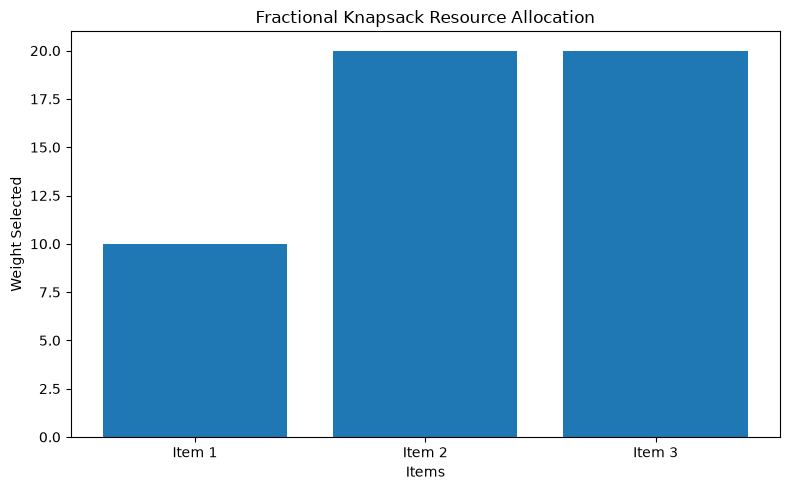

Allocation details:
{'Item': 'Item 1', 'Weight Taken': 10, 'Value Obtained': 60.0}
{'Item': 'Item 2', 'Weight Taken': 20, 'Value Obtained': 100.0}
{'Item': 'Item 3', 'Weight Taken': 20, 'Value Obtained': 80.0}


In [11]:

import matplotlib.pyplot as plt

# Predefined data
items = [
    (60, 10),
    (100, 20),
    (120, 30)
]
capacity = 50


def knapsack_allocation(items, capacity):
    sorted_items = sorted(
        enumerate(items, start=1),
        key=lambda x: x[1][0] / x[1][1],
        reverse=True
    )

    allocations = []

    for item_id, (value, weight) in sorted_items:
        if capacity <= 0:
            break

        taken = min(weight, capacity)
        allocations.append({
            "Item": f"Item {item_id}",
            "Weight Taken": taken,
            "Value Obtained": taken * value / weight
        })
        capacity -= taken

    return allocations


allocations = knapsack_allocation(items, capacity)

labels = [a["Item"] for a in allocations]
weights = [a["Weight Taken"] for a in allocations]

plt.figure(figsize=(8, 5))
plt.bar(labels, weights)
plt.title("Fractional Knapsack Resource Allocation")
plt.xlabel("Items")
plt.ylabel("Weight Selected")
plt.tight_layout()
plt.show()

print("Allocation details:")
for allocation in allocations:
    print(allocation)


## Activity Selection — Activity timeline

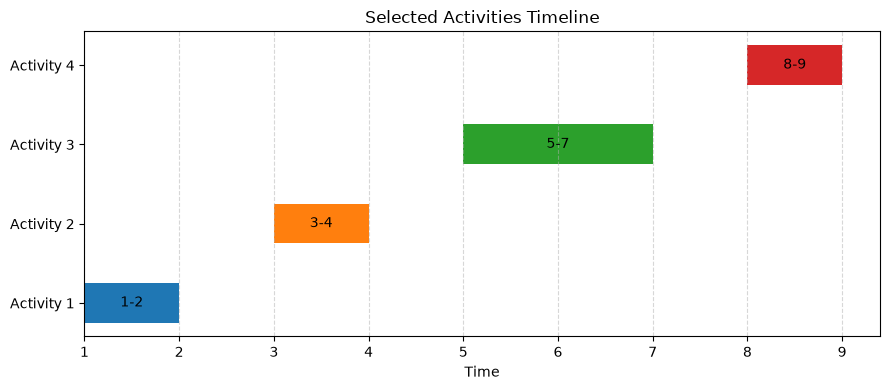

In [12]:

import matplotlib.pyplot as plt

activities = [
    (1, 2), (3, 4), (0, 6),
    (5, 7), (8, 9), (5, 9)
]

selected = activity_selection(activities)

fig, ax = plt.subplots(figsize=(9, 4))

for i, (start, finish) in enumerate(selected):
    ax.barh(
        i,
        finish - start,
        left=start,
        height=0.5
    )
    ax.text(
        (start + finish) / 2,
        i,
        f"{start}-{finish}",
        ha="center",
        va="center"
    )

ax.set_yticks(range(len(selected)))
ax.set_yticklabels(
    [f"Activity {i + 1}" for i in range(len(selected))]
)
ax.set_xlabel("Time")
ax.set_title("Selected Activities Timeline")
ax.grid(axis="x", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


## Huffman Compression

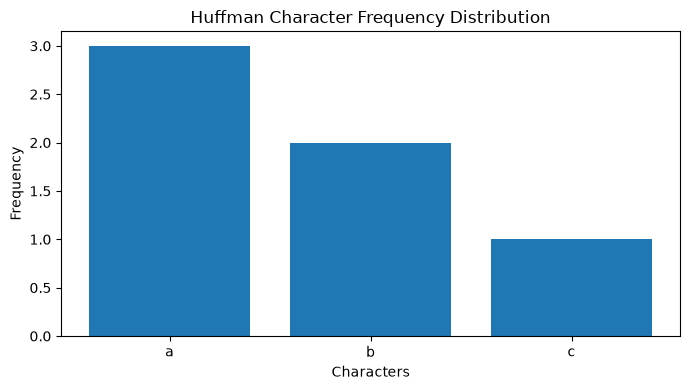

In [13]:

from collections import Counter
import matplotlib.pyplot as plt

text = "aaabbc"
frequencies = Counter(text)

plt.figure(figsize=(7, 4))
plt.bar(
    list(frequencies.keys()),
    list(frequencies.values())
)
plt.title("Huffman Character Frequency Distribution")
plt.xlabel("Characters")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


## Execution-time comparison graph

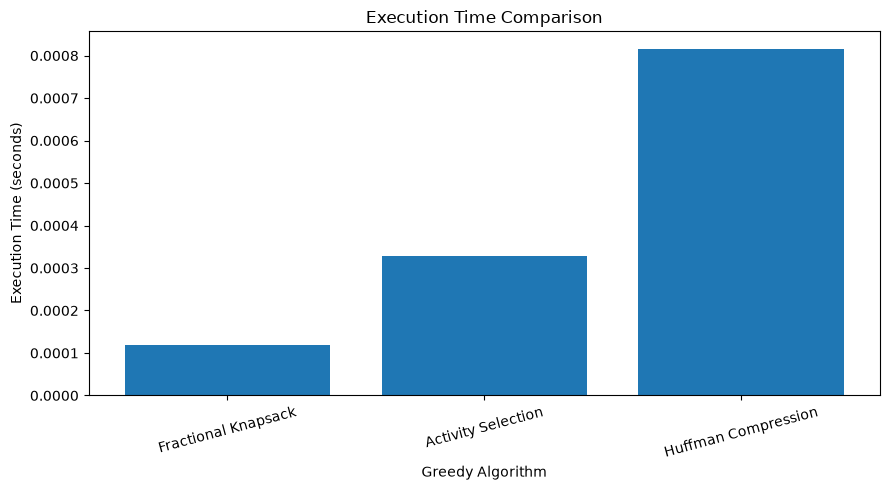

In [14]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    performance_df["Algorithm"],
    performance_df["Execution Time (seconds)"]
)

plt.title("Execution Time Comparison")
plt.xlabel("Greedy Algorithm")
plt.ylabel("Execution Time (seconds)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


## Memory-usage comparison graph

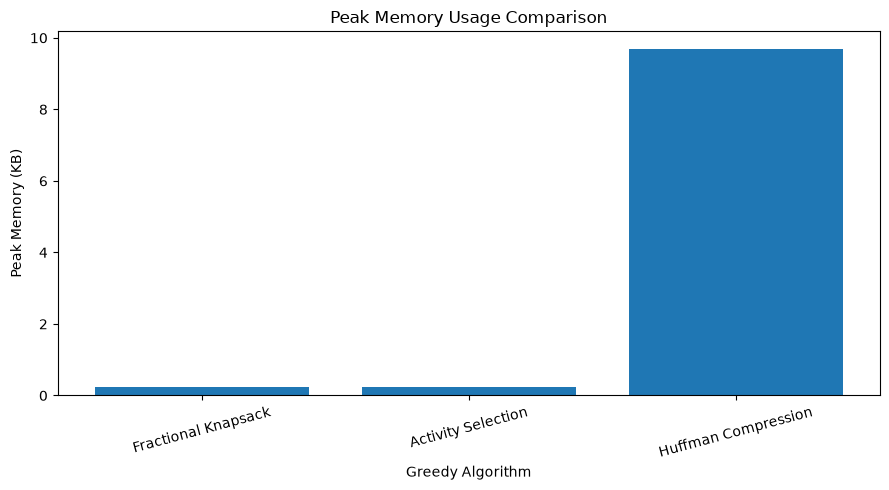

In [15]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    performance_df["Algorithm"],
    performance_df["Peak Memory (KB)"]
)

plt.title("Peak Memory Usage Comparison")
plt.xlabel("Greedy Algorithm")
plt.ylabel("Peak Memory (KB)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


## Save your visualizations

In [16]:

# Save the figures individually by creating them again
# and saving before plt.show().

print("To save a graph, add the following before plt.show():")
print('plt.savefig("graph_name.png", dpi=300, bbox_inches="tight")')


To save a graph, add the following before plt.show():
plt.savefig("graph_name.png", dpi=300, bbox_inches="tight")
